# AI Dermatology Assistant – Model Training & Evaluation

## Objective
Train and compare multiple machine learning classification algorithms for predicting skin diseases based on patient symptoms.

## Algorithms Used
- Logistic Regression
- Decision Tree Classifier
- Random Forest Classifier
- XGBoost Classifier

## Target Variable
`disease` (10 skin disease classes)

In [1]:
# ==========================================
# Import Required Libraries
# ==========================================

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

# Train-Test Split
from sklearn.model_selection import train_test_split

# Scaling
from sklearn.preprocessing import StandardScaler

# ML Models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Hyperparameter Tuning
from sklearn.model_selection import GridSearchCV

# Save Model
import joblib

All required libraries for model training, evaluation, visualization, hyperparameter tuning and model saving are imported.

In [2]:
# ==========================================
# Load Preprocessed Dataset
# ==========================================

df = pd.read_csv("../data/dermatology_preprocessed_dataset.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (6735, 30)


,body_area,itching_level,rash_type,skin_peeling,burning_sensation,swelling,fever,skin_color_change,pain,dry_skin,...,symptom_duration_days,severity_score,sleep_hours,water_intake_liters,gender_Male,gender_Other,skin_type_Dry,skin_type_Normal,skin_type_Oily,skin_type_Sensitive
0,3,1,5,1,0,1,0,0,1,0,...,30.0,5.0,7.3,3.1,0,0,1,0,0,0
1,0,1,5,1,0,1,0,1,1,1,...,60.0,7.0,5.5,1.6,1,0,0,0,1,0
2,4,3,2,0,0,1,0,1,1,0,...,5.0,5.0,7.1,2.0,1,0,0,1,0,0
3,4,1,7,1,1,1,0,0,0,1,...,2.0,8.0,5.9,1.3,1,0,0,0,1,0
4,6,1,0,0,0,1,0,1,0,0,...,90.0,5.0,5.5,2.6,0,1,0,0,0,1


The preprocessed dataset contains cleaned data, encoded categorical features and treated outliers. It is now ready for machine learning

In [3]:
# Dataset Information

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6735 entries, 0 to 6734
Data columns (total 30 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   body_area              6735 non-null   int64  
 1   itching_level          6735 non-null   int64  
 2   rash_type              6735 non-null   int64  
 3   skin_peeling           6735 non-null   int64  
 4   burning_sensation      6735 non-null   int64  
 5   swelling               6735 non-null   int64  
 6   fever                  6735 non-null   int64  
 7   skin_color_change      6735 non-null   int64  
 8   pain                   6735 non-null   int64  
 9   dry_skin               6735 non-null   int64  
 10  pus_or_discharge       6735 non-null   int64  
 11  family_history         6735 non-null   int64  
 12  allergy_history        6735 non-null   int64  
 13  recent_new_product     6735 non-null   int64  
 14  humidity_exposure      6735 non-null   int64  
 15  stress_level   

In [4]:
# Check Missing Values

df.isnull().sum().sum()

np.int64(0)

The dataset contains no missing values and all features are in numerical format, making it suitable for machine learning algorithms.

In [5]:
# ==========================================
# Separate Features and Target
# ==========================================

X = df.drop(columns=["disease"])
y = df["disease"]

In [6]:
print("Features Shape :", X.shape)
print("Target Shape   :", y.shape)

Features Shape : (6735, 29)
Target Shape   : (6735,)


X contains all patient symptoms and health attributes, while y contains the skin disease to be predicted.

In [7]:
# ==========================================
# Train-Test Split
# ==========================================

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

In [8]:
print("Training Set :", X_train.shape)
print("Testing Set  :", X_test.shape)

Training Set : (5388, 29)
Testing Set  : (1347, 29)


The dataset is split into 80% training and 20% testing data. Stratified sampling preserves the distribution of all disease classes.

In [9]:
# ==========================================
# Standard Scaling of Numerical Features
# ==========================================

numerical_cols = [
    "age",
    "bmi",
    "body_temperature",
    "symptom_duration_days",
    "severity_score",
    "sleep_hours",
    "water_intake_liters"
]

scaler = StandardScaler()

X_train[numerical_cols] = scaler.fit_transform(X_train[numerical_cols])
X_test[numerical_cols] = scaler.transform(X_test[numerical_cols])

print("Numerical columns scaled successfully!")

Numerical columns scaled successfully!


StandardScaler standardizes numerical features so that they have mean 0 and standard deviation 1. Scaling is fitted only on the training data and then applied to the testing data to avoid data leakage.

In [10]:
# ==========================================
# Save StandardScaler
# ==========================================

joblib.dump(scaler, "../models/scaler.pkl")

print("Scaler saved successfully!")

Scaler saved successfully!


The scaler is saved because user inputs in the Streamlit application must be transformed using the same scaler used during model training.

In [11]:
# ==========================================
# Store Model Accuracy
# ==========================================

model_accuracy = {}

A dictionary is created to store the accuracy of each machine learning model for comparison later.

In [12]:
# ==========================================
# Logistic Regression
# ==========================================

lr_model = LogisticRegression(max_iter=1000, random_state=42)

# Train
lr_model.fit(X_train, y_train)

# Predict
y_pred_lr = lr_model.predict(X_test)

# Accuracy
lr_accuracy = accuracy_score(y_test, y_pred_lr)
model_accuracy["Logistic Regression"] = lr_accuracy

print("Logistic Regression Accuracy:", round(lr_accuracy, 4))

Logistic Regression Accuracy: 0.7513


In [13]:
# Classification Report

print(classification_report(y_test, y_pred_lr))

              precision    recall  f1-score   support

           0       0.85      0.89      0.87       348
           1       1.00      0.94      0.97        18
           2       0.64      0.63      0.64       121
           3       0.68      0.83      0.75       242
           4       0.72      0.73      0.73       196
           5       0.89      0.87      0.88       151
           6       0.59      0.37      0.46       102
           7       0.48      0.31      0.38        74
           8       0.81      0.81      0.81        58
           9       0.76      0.70      0.73        37

    accuracy                           0.75      1347
   macro avg       0.74      0.71      0.72      1347
weighted avg       0.74      0.75      0.74      1347



<Figure size 800x600 with 0 Axes>

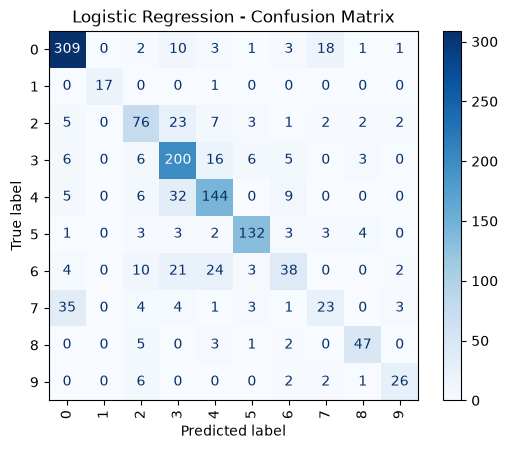

In [14]:
# Confusion Matrix

plt.figure(figsize=(8,6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_lr,
    cmap="Blues",
    xticks_rotation=90
)

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

Logistic Regression is used as a baseline multiclass classification model. It predicts one of the ten skin diseases based on the patient's symptoms.

In [15]:
# ==========================================
# Decision Tree Classifier
# ==========================================

dt_model = DecisionTreeClassifier(random_state=42)

# Train
dt_model.fit(X_train, y_train)

# Predict
y_pred_dt = dt_model.predict(X_test)

# Accuracy
dt_accuracy = accuracy_score(y_test, y_pred_dt)
model_accuracy["Decision Tree"] = dt_accuracy

print("Decision Tree Accuracy:", round(dt_accuracy, 4))

Decision Tree Accuracy: 0.8471


In [16]:
print(classification_report(y_test, y_pred_dt))

              precision    recall  f1-score   support

           0       0.91      0.90      0.91       348
           1       0.86      1.00      0.92        18
           2       0.74      0.74      0.74       121
           3       0.89      0.86      0.88       242
           4       0.81      0.90      0.85       196
           5       0.95      0.92      0.94       151
           6       0.77      0.72      0.74       102
           7       0.67      0.66      0.67        74
           8       0.74      0.74      0.74        58
           9       0.84      0.84      0.84        37

    accuracy                           0.85      1347
   macro avg       0.82      0.83      0.82      1347
weighted avg       0.85      0.85      0.85      1347



<Figure size 800x600 with 0 Axes>

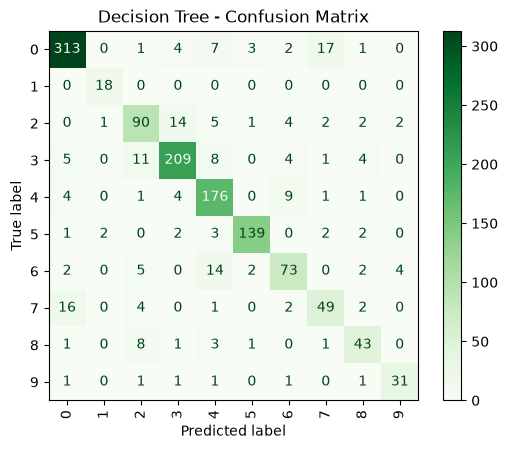

In [17]:
plt.figure(figsize=(8,6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_dt,
    cmap="Greens",
    xticks_rotation=90
)

plt.title("Decision Tree - Confusion Matrix")
plt.show()

Decision Tree learns decision rules from symptoms and classifies patients into different skin diseases. It is easy to interpret but may overfit the training data.

In [18]:
# ==========================================
# Random Forest Classifier
# ==========================================

rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

# Train
rf_model.fit(X_train, y_train)

# Predict
y_pred_rf = rf_model.predict(X_test)

# Accuracy
rf_accuracy = accuracy_score(y_test, y_pred_rf)
model_accuracy["Random Forest"] = rf_accuracy

print("Random Forest Accuracy:", round(rf_accuracy, 4))

Random Forest Accuracy: 0.8946


In [19]:
print(classification_report(y_test, y_pred_rf))

              precision    recall  f1-score   support

           0       0.93      0.97      0.95       348
           1       1.00      1.00      1.00        18
           2       0.78      0.80      0.79       121
           3       0.91      0.93      0.92       242
           4       0.87      0.91      0.89       196
           5       0.94      0.96      0.95       151
           6       0.84      0.75      0.79       102
           7       0.87      0.70      0.78        74
           8       0.94      0.79      0.86        58
           9       0.88      0.81      0.85        37

    accuracy                           0.89      1347
   macro avg       0.90      0.86      0.88      1347
weighted avg       0.89      0.89      0.89      1347



<Figure size 800x600 with 0 Axes>

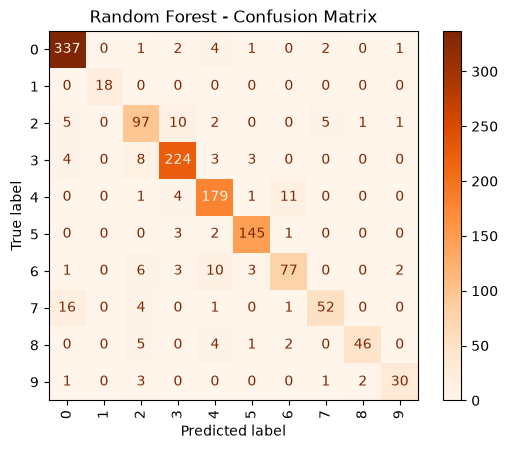

In [20]:
plt.figure(figsize=(8,6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    cmap="Oranges",
    xticks_rotation=90
)

plt.title("Random Forest - Confusion Matrix")
plt.show()

Random Forest combines multiple decision trees to improve prediction accuracy and reduce overfitting. It is one of the strongest algorithms for structured healthcare datasets.

In [21]:
# ==========================================
# XGBoost Classifier
# ==========================================

xgb_model = XGBClassifier(
    objective="multi:softmax",
    num_class=10,
    eval_metric="mlogloss",
    random_state=42
)

# Train
xgb_model.fit(X_train, y_train)

# Predict
y_pred_xgb = xgb_model.predict(X_test)

# Accuracy
xgb_accuracy = accuracy_score(y_test, y_pred_xgb)
model_accuracy["XGBoost"] = xgb_accuracy

print("XGBoost Accuracy:", round(xgb_accuracy, 4))

XGBoost Accuracy: 0.9042


In [22]:
print(classification_report(y_test, y_pred_xgb))

              precision    recall  f1-score   support

           0       0.95      0.97      0.96       348
           1       1.00      1.00      1.00        18
           2       0.83      0.84      0.84       121
           3       0.91      0.89      0.90       242
           4       0.89      0.93      0.91       196
           5       0.95      0.96      0.96       151
           6       0.85      0.80      0.82       102
           7       0.86      0.77      0.81        74
           8       0.81      0.83      0.82        58
           9       0.89      0.86      0.88        37

    accuracy                           0.90      1347
   macro avg       0.89      0.89      0.89      1347
weighted avg       0.90      0.90      0.90      1347



<Figure size 800x600 with 0 Axes>

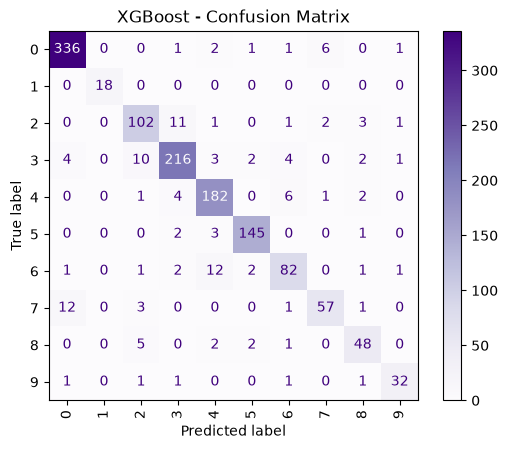

In [23]:
plt.figure(figsize=(8,6))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_xgb,
    cmap="Purples",
    xticks_rotation=90
)

plt.title("XGBoost - Confusion Matrix")
plt.show()

XGBoost is a boosting algorithm that builds trees sequentially, correcting previous mistakes. It often achieves high accuracy on multiclass tabular datasets.

In [24]:
# ==========================================
# Accuracy Comparison
# ==========================================

accuracy_df = pd.DataFrame(
    model_accuracy.items(),
    columns=["Model", "Accuracy"]
)

accuracy_df = accuracy_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

accuracy_df

,Model,Accuracy
0,XGBoost,0.904232
1,Random Forest,0.894581
2,Decision Tree,0.847068
3,Logistic Regression,0.751299


C:\Users\ABC\AppData\Local\Temp\ipykernel_9188\1446721906.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


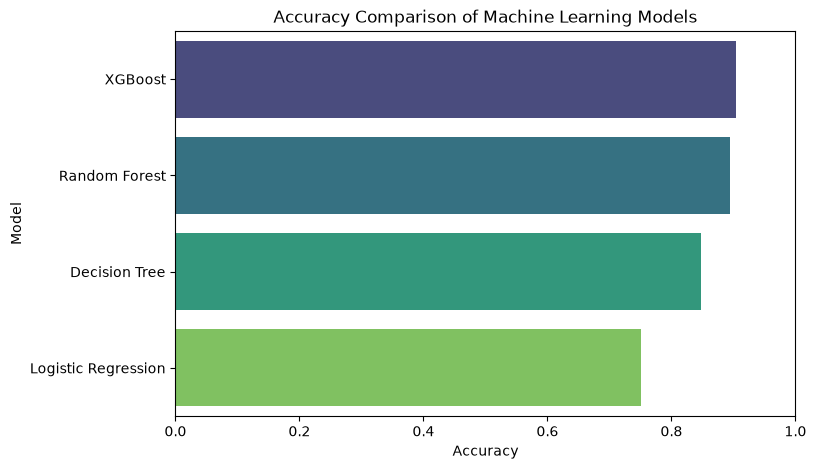

In [25]:
# ==========================================
# Model Accuracy Comparison
# ==========================================

plt.figure(figsize=(8,5))

sns.barplot(
    data=accuracy_df,
    x="Accuracy",
    y="Model",
    palette="viridis"
)

plt.title("Accuracy Comparison of Machine Learning Models")
plt.xlim(0,1)

plt.show()

The bar chart compares the prediction accuracy of all machine learning models. The model with the highest accuracy will be selected for hyperparameter tuning.

# Hyperparameter Tuning using GridSearchCV

The XGBoost model achieved the highest baseline accuracy (90.42%). Therefore, GridSearchCV is used to find the best combination of hyperparameters and improve the model's performance.

Why GridSearchCV? <br>Since the hyperparameter search space is relatively small (24 combinations), GridSearchCV was chosen over RandomizedSearchCV to exhaustively evaluate every parameter combination and obtain the optimal XGBoost model.

In [26]:
# ==========================================
# Hyperparameter Tuning - XGBoost
# ==========================================

param_grid = {
    "n_estimators": [100, 200],
    "max_depth": [4, 6, 8],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0]
}

grid_search = GridSearchCV(
    estimator=XGBClassifier(
        objective="multi:softmax",
        num_class=10,
        eval_metric="mlogloss",
        random_state=42
    ),
    param_grid=param_grid,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train, y_train)

print("Best Parameters:")
print(grid_search.best_params_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best Parameters:
{'learning_rate': 0.05, 'max_depth': 4, 'n_estimators': 200, 'subsample': 0.8}


GridSearchCV performs cross-validation on multiple combinations of hyperparameters and selects the combination that produces the highest validation accuracy.

In [27]:
# ==========================================
# Best Tuned XGBoost Model
# ==========================================

best_xgb = grid_search.best_estimator_

y_pred_best = best_xgb.predict(X_test)

best_accuracy = accuracy_score(y_test, y_pred_best)

print("Tuned XGBoost Accuracy:", round(best_accuracy, 4))

Tuned XGBoost Accuracy: 0.9176


Precision, Recall, F1-Score and Support are calculated for each skin disease class to evaluate multiclass performance.

<Figure size 900x700 with 0 Axes>

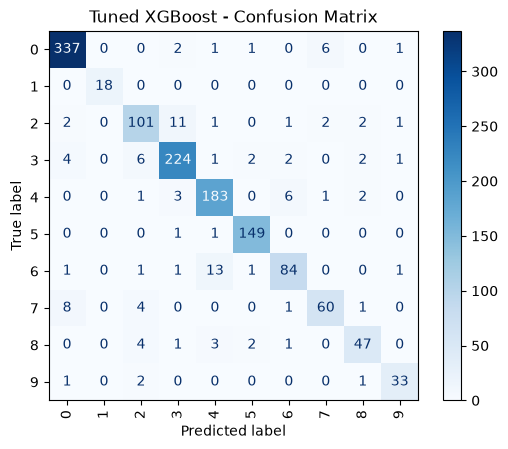

In [28]:
# ==========================================
# Confusion Matrix
# ==========================================

plt.figure(figsize=(9,7))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_best,
    cmap="Blues",
    xticks_rotation=90
)

plt.title("Tuned XGBoost - Confusion Matrix")
plt.show()

The confusion matrix shows how many patients from each disease class were predicted correctly and where misclassifications occurred.

C:\Users\ABC\AppData\Local\Temp\ipykernel_9188\1955377815.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


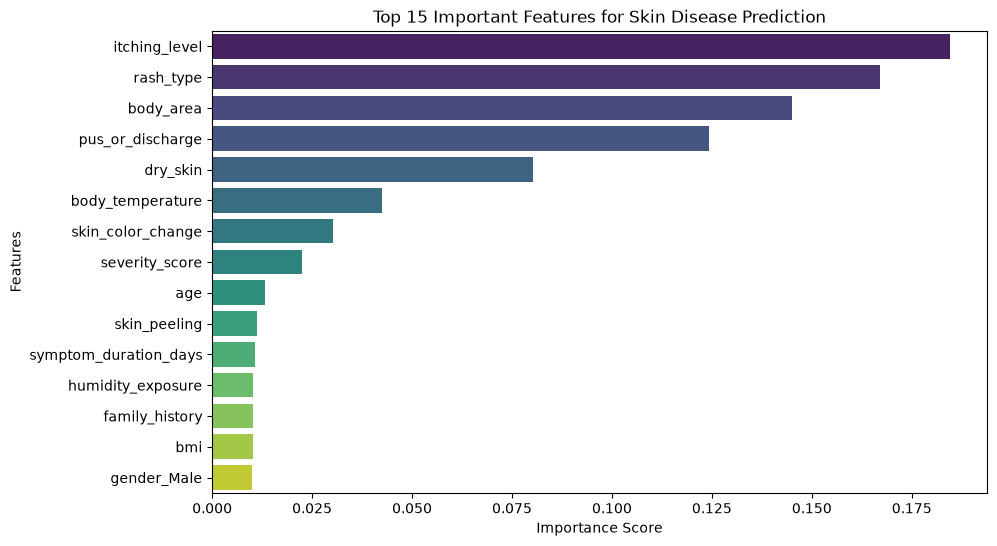

,Feature,Importance
1,itching_level,0.184619
2,rash_type,0.166984
0,body_area,0.144949
10,pus_or_discharge,0.124362
9,dry_skin,0.080320
18,body_temperature,0.042502
7,skin_color_change,0.030302
20,severity_score,0.022534
16,age,0.013119
3,skin_peeling,0.011111


In [29]:
# ==========================================
# Top 15 Important Features
# ==========================================

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_xgb.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

plt.figure(figsize=(10,6))

sns.barplot(
    data=feature_importance.head(15),
    x="Importance",
    y="Feature",
    palette="viridis"
)

plt.title("Top 15 Important Features for Skin Disease Prediction")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

feature_importance.head(15)

In [30]:
# ==========================================
# Accuracy Before vs After Tuning
# ==========================================

comparison = pd.DataFrame({
    "Model": ["XGBoost (Before Tuning)", "XGBoost (After Tuning)"],
    "Accuracy": [xgb_accuracy, best_accuracy]
})

comparison

,Model,Accuracy
0,XGBoost (Before Tuning),0.904232
1,XGBoost (After Tuning),0.917595


C:\Users\ABC\AppData\Local\Temp\ipykernel_9188\1906289973.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


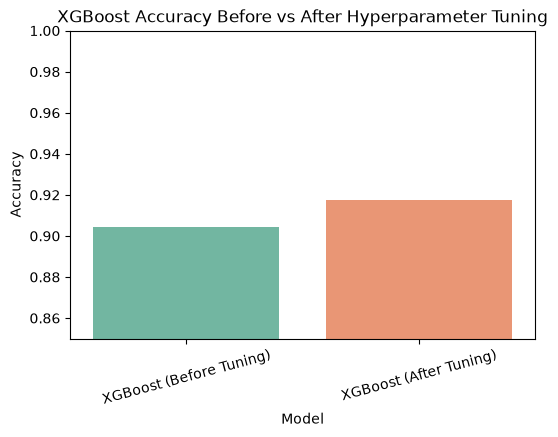

In [31]:
plt.figure(figsize=(6,4))

sns.barplot(
    data=comparison,
    x="Model",
    y="Accuracy",
    palette="Set2"
)

plt.ylim(0.85, 1.0)
plt.title("XGBoost Accuracy Before vs After Hyperparameter Tuning")
plt.xticks(rotation=15)

plt.show()

# Hyperparameter Tuning - Random Forest

Random Forest is tuned using GridSearchCV to find the optimal tree depth, number of trees and split criteria.

In [32]:
# ==========================================
# Hyperparameter Tuning - Random Forest
# ==========================================

rf_params = {
    "n_estimators": [100, 200],
    "max_depth": [10, 20, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2],
    "max_features": ["sqrt", "log2"]
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=rf_params,
    cv=3,
    scoring="accuracy",
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest Parameters:")
print(rf_grid.best_params_)

Fitting 3 folds for each of 48 candidates, totalling 144 fits
Best Random Forest Parameters:
{'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 200}


In [33]:
best_rf = rf_grid.best_estimator_

y_pred_rf_best = best_rf.predict(X_test)

rf_best_accuracy = accuracy_score(y_test, y_pred_rf_best)

print("Random Forest Accuracy After Tuning:", round(rf_best_accuracy, 4))

Random Forest Accuracy After Tuning: 0.8968


Hyperparameter tuning improves the model by selecting the most suitable combination of parameters.

# Comparison of Tuned Models

Both Random Forest and XGBoost were tuned using GridSearchCV. Their final accuracies are compared to identify the best-performing model for deployment in the AI Dermatology Assistant.

In [34]:
# ==========================================
# Compare Tuned Random Forest vs Tuned XGBoost
# ==========================================

comparison_df = pd.DataFrame({
    "Model": ["Random Forest (Tuned)", "XGBoost (Tuned)"],
    "Accuracy": [
        round(rf_best_accuracy, 4),
        round(best_accuracy, 4)
    ]
})

# Sort by highest accuracy
comparison_df = comparison_df.sort_values(
    by="Accuracy",
    ascending=False
).reset_index(drop=True)

comparison_df

,Model,Accuracy
0,XGBoost (Tuned),0.9176
1,Random Forest (Tuned),0.8968


C:\Users\ABC\AppData\Local\Temp\ipykernel_9188\3113873758.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


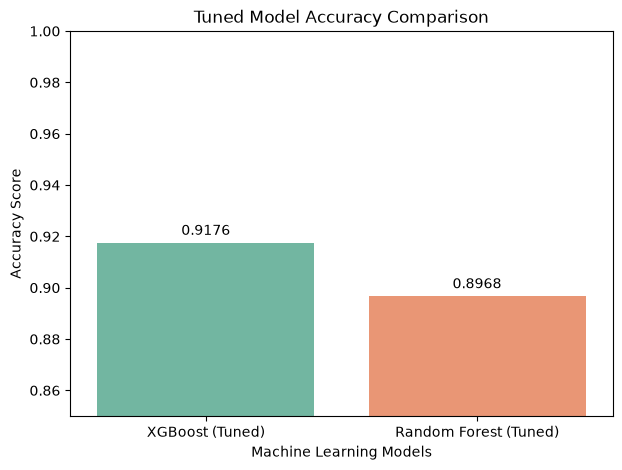

In [35]:
# ==========================================
# Accuracy Comparison Bar Chart
# ==========================================

plt.figure(figsize=(7,5))

sns.barplot(
    data=comparison_df,
    x="Model",
    y="Accuracy",
    palette="Set2"
)

plt.title("Tuned Model Accuracy Comparison")
plt.xlabel("Machine Learning Models")
plt.ylabel("Accuracy Score")
plt.ylim(0.85, 1.00)

# Show accuracy values on bars
for index, value in enumerate(comparison_df["Accuracy"]):
    plt.text(index, value + 0.003, str(value), ha="center", fontsize=10)

plt.show()

In [36]:
# ==========================================
# Select Best Performing Model
# ==========================================

if best_accuracy > rf_best_accuracy:
    final_model = best_xgb
    final_model_name = "XGBoost"
    final_accuracy = best_accuracy
else:
    final_model = best_rf
    final_model_name = "Random Forest"
    final_accuracy = rf_best_accuracy

print(f"Best Model Selected : {final_model_name}")
print(f"Final Accuracy      : {round(final_accuracy, 4)}")

Best Model Selected : XGBoost
Final Accuracy      : 0.9176


After hyperparameter tuning, the accuracies of both models were compared. The model with the highest testing accuracy was selected as the final model for deployment in the Streamlit application.

In [37]:
# ==========================================
# Save Best Final Model
# ==========================================

joblib.dump(final_model, "../models/dermatology_model.pkl")

print(f"{final_model_name} model saved successfully!")

XGBoost model saved successfully!


In [38]:
# ==========================================
# Save Feature Names
# ==========================================

joblib.dump(list(X_train.columns), "../models/feature_names.pkl")

print("Feature names saved successfully!")

Feature names saved successfully!
